# Monte Carlo Options Pricing Notebook

This notebook builds and validates a Monte Carlo option pricing engine in Python (`pricing.py`) and applies it to a live NVIDIA put option. The Monte Carlo and Longstaff-Schwartz (LSM) methods are checked against the Black-Scholes closed-form price, which serves as the control. Each result is reported with its simulation error, not just a point estimate.

## Key results
- **Convergence:** Monte Carlo call prices converge to Black-Scholes at the expected 1/√n rate. The standard error is about $0.04 at 100,000 simulated paths, and the 95% confidence interval contained the true price in 94.8% of 1,000 independent runs.
- **Variance reduction:** Antithetic variates cut the standard deviation of the price estimates by 23.5% (0.436 to 0.334) at the same number of paths.
- **American options:** LSM prices an American put at $8.74 vs. $7.92 for the European put on the same paths, an early-exercise premium of $0.82. The premium falls steeply from $2.96 at 5% volatility to about $0.88 at 17%, then levels off.
- **Live market data:** On a live NVDA put (strike $145, 86 days to expiry), historical volatility (50.8%) gave a model price of $14.45-$14.59 against a market mid of $17.18. Using implied volatility solved from that mid (60.8%) recovers the mid by construction. This is a calibration rather than an independent test.

## Structure

1. Black-Scholes closed form (call and put) and put-call parity
2. Monte Carlo pricing with standard errors, a coverage test, and antithetic variates
3. Longstaff-Schwartz for American puts and the premium vs. volatility
4. Application to live NVDA data via `yfinance`
5. Limitations

All random cells are seeded to reproduce the exact same results when rerun. The market section was captured on 2026-11-25 and saved to `market_snapshot.json`. Rerunning it pulls fresh data which gives different numbers.

In [1]:
import os
import sys
import json
import datetime
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf
from scipy.optimize import brentq

ROOT = Path.cwd() if (Path.cwd() / 'pricing.py').exists() else Path.cwd().parent
sys.path.append(str(ROOT))

from pricing import (black_scholes_call, black_scholes_put, monte_carlo_call,
                     antithetic_monte_carlo_call, monte_carlo_put, LSM_put)

IMAGES = ROOT / 'images'
IMAGES.mkdir(exist_ok=True)
np.random.seed(42)

In [2]:
S0 = 100                    #current stock price
K = 105                     #strike price
T = 1.0                     #time to maturity (yrs)
r = 0.05                    #risk-free rate
sigma = 0.2                 #volatility
n_simulations = 100000      #number of simulations
n_steps = 50                #number of time steps

In [3]:
def mc_call_with_se(S0, K, T, r, sigma, n, seed=None):
    rng = np.random.default_rng(seed)
    Z = rng.standard_normal(n)
    ST = S0 * np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
    payoff = np.exp(-r*T) * np.maximum(ST - K, 0)
    return payoff.mean(), payoff.std(ddof=1) / np.sqrt(n)

## Black-Scholes Call Option

This function uses the Black-Scholes formula to estimate the fair value of a European call option given parameters (current stock price, strike price, time until expiration (yrs), risk-free rate, and volatility). This is a non-simulated solution.

I am using this as a control to compare the performance of the Monte Carlo simulation later in this notebook. If the simulation converges to the calculated Black-Scholes value as the number of simulated paths increase, then the program functions as intended.

In [4]:
bs_price = black_scholes_call(S0, K, T, r, sigma)
print(f"Black-Scholes price: {bs_price:.4f}")

Black-Scholes price: 8.0214


## Monte Carlo Call Option Simulation

This function simulates many possible final stock prices to estimate the value of a European call option. A random shock is generated from a standard normal distribution for each path. Using this, the stock's volatility and the risk-free rate, the ending stock price of each path can be simulated. Each option's payoff is then calculated, averaged, and then discounted back to today's value to estimate the fair price.

In [5]:
np.random.seed(1)

mc_price = monte_carlo_call(S0, K, T, r, sigma, n_simulations)
print(f"Monte Carlo price: {mc_price:.4f}")
print(f"Difference from Black-Scholes: {abs(mc_price - bs_price):.4f}")    #print difference between the two methods

Monte Carlo price: 8.0605
Difference from Black-Scholes: 0.0391


In [6]:
p, se = mc_call_with_se(S0, K, T, r, sigma, n_simulations, seed=1)
print(f"Monte Carlo: {p:.4f}    standard error: {se:.4f}    95% CI: [{p-1.96*se:.4f}, {p+1.96*se:.4f}]")
print(f"Black-Scholes {bs_price:.4f} inside the CI: {p-1.96*se <= bs_price <= p+1.96*se}")

Monte Carlo: 7.9378    standard error: 0.0416    95% CI: [7.8563, 8.0194]
Black-Scholes 8.0214 inside the CI: False


In [7]:
hits = 0
for s in range(1000):
    p, se = mc_call_with_se(S0, K, T, r, sigma, n_simulations, seed=s)
    hits += (p -1.96*se <= bs_price <= p + 1.96*se)
print(f"95% CI contained the Black-Scholes price in {hits/10:.1f}% of 1,000 runs")

95% CI contained the Black-Scholes price in 94.8% of 1,000 runs


A 95% interval misses about 1 run in 20, and this seed happens to be one of them. The cell above shows the interval covers the Black-Scholes price in 94.8% of 1,000 runs.

The chart below graphs 20 points, each representing the average discounted payoff across n simulations, where n increases along the x-axis. The number of simulations for each point is evenly spaced out on a logarithmic scale. The shaded region is a 95% confidence interval.

As predicted above, when the number of simulations increase, the average simulated fair price for the call option converges to the value calculated by the Black-Scholes formula.

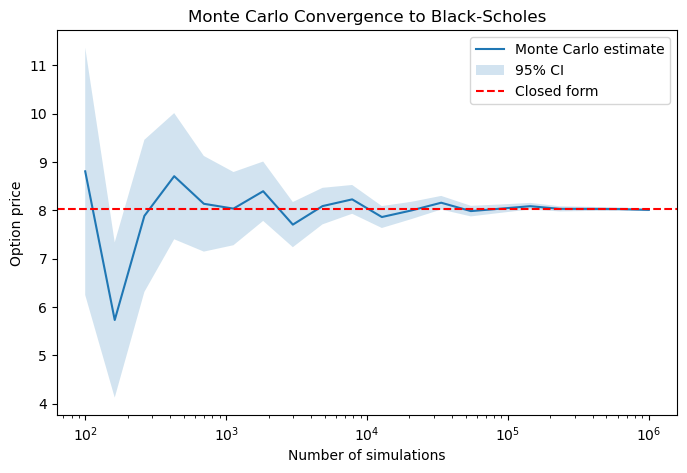

In [8]:
sim_counts = np.logspace(2, 6, 20).astype(int)   #gets range, 20 points equally spaced along log scale between 100 and 1,000,000
results = [mc_call_with_se(S0, K, T, r, sigma, n, seed=i) for i, n in enumerate(sim_counts)] 
prices = np.array([p for p, _ in results])
ses = np.array([s for _, s in results])

#neatly plot the 20 points found with the monte carlo method
plt.figure(figsize=(8,5))
plt.plot(sim_counts, prices, label='Monte Carlo estimate')
plt.fill_between(sim_counts, prices - 1.96*ses, prices +1.96*ses, alpha=0.2, label='95% CI')
plt.axhline(bs_price, color='red', linestyle='--', label='Closed form')
plt.xscale('log')
plt.xlabel('Number of simulations')
plt.ylabel('Option price')
plt.title('Monte Carlo Convergence to Black-Scholes')                                       #save plot
plt.legend()
plt.savefig(IMAGES / 'price_convergence_plot.png', dpi=150, bbox_inches='tight')
plt.show()

The Monte Carlo Simulation's error is expected to shrink proportionally to   1/sqrt(n) as the number of simulations increases, according to the Central Limit Theorem. The below chart, showing absolute error vs. number of simulations (both on a log scale), demonstrates a general downward, negative trend that is consistent with this relationship. Note that there is always noise due to the independent, random nature of each batch of simulations.

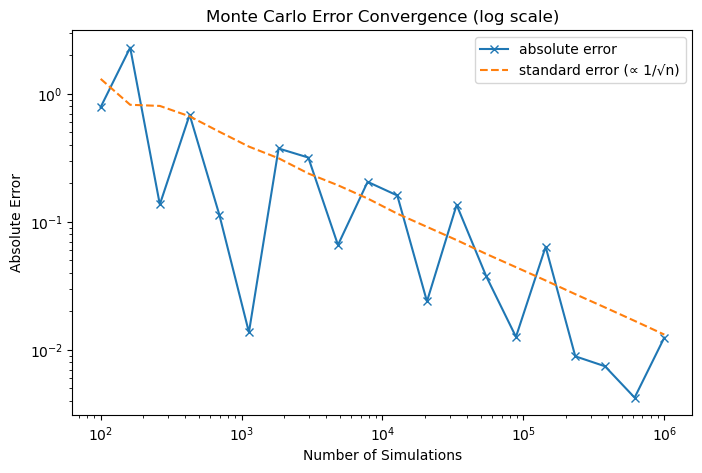

In [9]:
#neatly plot the error convergence
err = np.abs(np.array(prices) - bs_price)
plt.figure(figsize=(8,5))
plt.loglog(sim_counts, err, marker ='x', label='absolute error')
plt.loglog(sim_counts, ses, linestyle='--', label='standard error (∝ 1/√n)')
plt.xlabel('Number of Simulations')
plt.ylabel('Absolute Error')
plt.title('Monte Carlo Error Convergence (log scale)')
plt.legend()
plt.show()

## Applying Antithetic Variance Reduction

The Monte Carlo simulation can be further improved using antithetic variates to reduce variance. For every random shock Z randomly generated, a second path is generated with shock -Z. By pairing the two negatively correlated shocks in this manner, extreme outcomes partially cancel when averaged. This generates more precise data with the same number of paths while needing only half the number of independently random draws.

To test the variance reduction technique, both the plain and antithetic Monte Carlo simulations were run 200 times each, with 1,000 simulations in each run. The resulting standard deviations found the antithetic MC standard deviation (0.334) was about a 23.5% reduction from the normal MC standard deviation (0.436).

In [10]:
np.random.seed(7)
plain = [monte_carlo_call(S0, K, T, r, sigma, 1000) for _ in range(200)]                       #run each method 200 times, 1000 simulations per run
antithetic = [antithetic_monte_carlo_call(S0, K, T, r, sigma, 1000) for _ in range(200)]

print(f"Standard deviation of plain Monte Carlo: {np.std(plain):.6f}")                         #print results
print(f"Standard deviation of antithetic Monte Carlo: {np.std(antithetic):.6f}")
print(f"Reduction in standard deviation: {1 - np.std(antithetic)/np.std(plain):.1%}")


Standard deviation of plain Monte Carlo: 0.436186
Standard deviation of antithetic Monte Carlo: 0.333773
Reduction in standard deviation: 23.5%


The histogram below shows two separate data sets, one representing the simulations from the plain Monte Carlo (blue) and one representing the antithetic Monte Carlo (red). The plain data produces a wider and shorter cluster of data compared to the taller and thinner cluster from the antithetic data. The narrower spread confirms that antithetic variates were successful in reducing the variance of the price estimate.

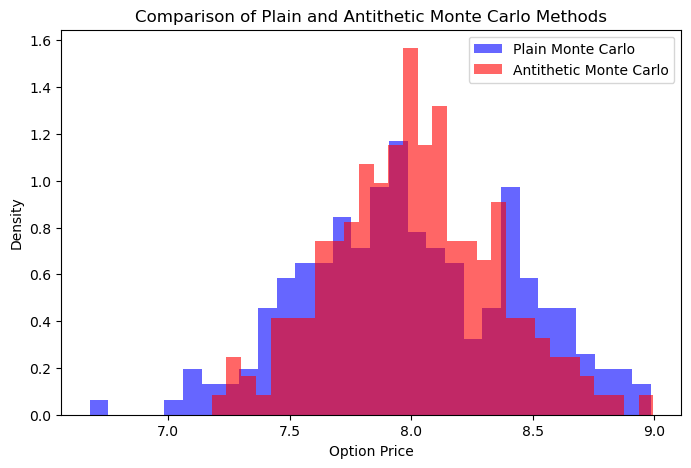

In [11]:
#neatly plot overlapping histograms for each method's data
plt.figure(figsize=(8, 5))
plt.hist(plain, bins=30, alpha=0.6, label='Plain Monte Carlo', color='blue', density=True)
plt.hist(antithetic, bins=30, alpha=0.6, label='Antithetic Monte Carlo', color='red', density=True)
plt.xlabel('Option Price')
plt.ylabel('Density')
plt.title('Comparison of Plain and Antithetic Monte Carlo Methods')
plt.legend()
plt.savefig(IMAGES / 'antithetic_comparison.png', dpi=150, bbox_inches='tight')   #save plot
plt.show()

## Black-Scholes Put Option

This function uses the Black-Scholes formula to estimate the fair price of a European put option. It uses the same d1 and d2 calculations as the call option formula but with the signs flipped within the normal CDF terms along with the two terms swapped in order.

Note that this price can also be derived from the call price using put-call parity (checked in the cell below):

put = call - S0 + Ke^(-rT)

In [12]:
black_scholes_p = black_scholes_put(S0, K, T, r, sigma)

print(f"Black-Scholes Put Price: {black_scholes_p:.6f}")

Black-Scholes Put Price: 7.900442


In [29]:
call = black_scholes_call(S0, K, T, r, sigma)       #call both Black-Scholes functions with same parameters
put = black_scholes_put(S0, K, T, r, sigma)

#put-call parity check, check if left side equals right side for: call - put = S0 - Ke^(-rT)
left = call - put
right = S0 - K*np.exp(-r*T)
print(f"Call - Put: {left:.6f}")
print(f"S0 - Ke^(-rT): {right:.6f}")
print("Closed-form parity holds:", np.isclose(left, right))

Call - Put: 0.120910
S0 - Ke^(-rT): 0.120910
Closed-form parity holds: True


## Monte Carlo Put Option Price Simulation

This function is a Monte Carlo simulation to estimate the fair price for a European put option. It mirrors the Monte Carlo call price simulation but instead of taking the max between the stock value minus the strike price and 0, it takes the max between the strike price minus the stock value and 0. 

Similarly to the call version, this simulation can be compared with the Black-Scholes put formula since the simulated price and Black-Scholes price should converge as the number of simulations increase. 

In [14]:
np.random.seed(2)

monte_carlo_p = monte_carlo_put(S0, K, T, r, sigma, n_simulations)

print(f"Monte Carlo Put Price: {monte_carlo_p:.6f}")
print(f"Difference from Black-Scholes: {abs(black_scholes_p - monte_carlo_p):.6f}")     #print difference between the two methods

Monte Carlo Put Price: 7.941511
Difference from Black-Scholes: 0.041069


In [30]:
rng = np.random.default_rng(3)
Z = rng.standard_normal(n_simulations)
ST = S0 * np.exp((r - 0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)
d = np.exp(-r*T) * (np.maximum(ST - K, 0) - np.maximum (K - ST, 0))
print(f"Simulated Call - Put: {d.mean():.4f} ± {1.96*d.std(ddof=1)/np.sqrt(len(d)):.4f} (95%) vs. S0 - Ke^(-rT): {S0 - K*np.exp(-r*T):.4f}")

Simulated Call - Put: 0.1321 ± 0.1251 (95%) vs. S0 - Ke^(-rT): 0.1209


Simulated call - put is 0.132 ± 0.125, which contains the theoretical 0.121 within uncertainty. The width of the interval is caused by the two numbers coming from noisy estimates.

## Longstaff-Schwartz: American Put Option Price

To price an American option, the stock's price at every point in time is needed as the option can be exercised early. The first step is handled by `sim_paths` in `pricing.py`. 

A grid of 0 value placeholders is created with each row representing a simulated path and each column representing an individual time step. The first column is filled with the current stock price, and the following columns are filled in one time step at a time using the stock price simulated from Geometric Brownian Motion. This continues until the paths reach expiration.


This function uses backward induction and quadratic regressions to decide, at each time step for each simulated path, if an early exercise is optimal. It begins at expiration and works backwards, going by one step at a time. It takes the immediate exercise payoff and compares it to a regression-estimated value for holding the option.

Every path's final realized cash flow is then discounted by accounting for the time value of money so that it can be more accurately compared to present value. This final price is then averaged across every simulated path to find the fair value today.

The American put is worth $8.74 vs. $7.92 for the European put on the same paths, an early-exercise premium of $0.82.

In [16]:
np.random.seed(4)

am, eu = LSM_put(S0, K, T, r, sigma, n_steps, n_simulations, return_european=True)
print(f"American: {am:.4f}      European (same paths): {eu:.4f}     Premium: {am-eu:.4f}")

American: 8.7361      European (same paths): 7.9180     Premium: 0.8181


## American Early Exercise Premium vs. Volatility

This plot shows the early exercise premium American put options carry over European put options, and how that premium changes with volatility.

At low volatility, the early exercise premium is higher: with little expected stock movement, exercising today guarantees the current profit and allows the cash to begin earning interest today.

At high volatilities, the early exercise premium is smaller: there is an increased chance for the stock to drop further prior to expiration. This increases the value to wait as a larger payoff than today's smaller one is possible.

This premium falls sharply before leveling off. It drops from $2.96 at σ = 5% to $0.88 at about 17%. It then flattens at around $0.58-0.68 above 35% volatility with approximately ±$0.03 of noise.

This result might seem counterintuitive at first, but reflects a trade-off: the interest earned by exercising early versus the option's time value from waiting on a stock with a high volatility.

[2.963 1.593 1.101 0.883 0.8   0.731 0.682 0.678 0.653 0.68  0.631 0.661
 0.578 0.653 0.638]


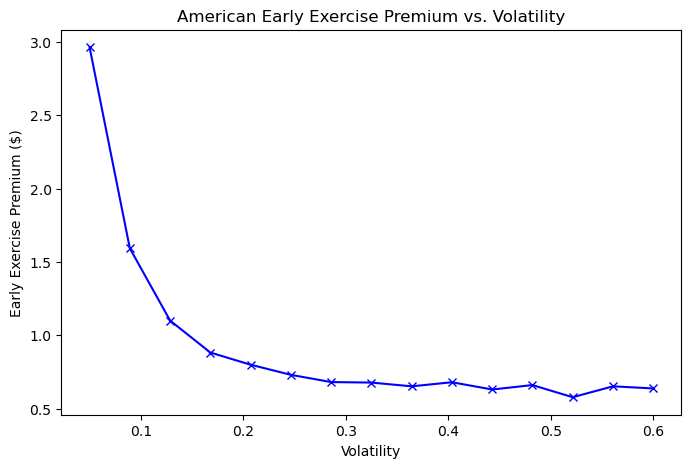

In [17]:
np.random.seed(5)
sigma_values = np.linspace(0.05, 0.6, 15)


prem = []
for vol in sigma_values:
    am, eu = LSM_put(S0, K, T, r, vol, n_steps, n_simulations, return_european=True)
    prem.append(am - eu)
prem = np.array(prem)

print(np.round(prem, 3))

#neatly plot the American Early Exercise Premium vs. volatility to show the relationship between the two
plt.figure(figsize=(8,5))
plt.plot(sigma_values, prem, marker='x', color='blue')
plt.xlabel("Volatility")
plt.ylabel("Early Exercise Premium ($)")
plt.title("American Early Exercise Premium vs. Volatility")
plt.savefig(IMAGES / 'early_exercise_premium.png', dpi=150, bbox_inches='tight')   #save plot
plt.show()

## Applying to Real Market Data

Everything up to this point has used predetermined parameters to demonstrate and verify all of the tested methods. Real market data is far messier and unpredictable.

Now that the methods were confirmed with the simple examples, this section applies them to actual data from the yfinance library.

For this test, NVIDIA's stock was picked due to its popularity and high trading volume. The current stock price was pulled from the most recent closing price.

Then, the historical volatility was computed using the past year's daily log returns (the natural log of the ratio of each day's closing price to the prior day's closing price). This value was then annualized using sqrt(252) (typical number of trading days in a year). This gives a volatility that is used later in this notebook.

In [18]:
ticker = "NVDA"                                                 #stock, picked NVIDIA for this example
stock = yf.Ticker(ticker)

S0_real = stock.history(period="1d")['Close'].iloc[-1]          #grabs current stock price at last close

hist = stock.history(period="1y")
log_returns = np.log(hist['Close'] / hist['Close'].shift(1))    #gets log of returns
sig_real = log_returns.std() * np.sqrt(252)                     #annualized volatility

print(f"Real {ticker} stock price: ${S0_real:.2f}")
print(f"Annualized {ticker} historical volatility: {sig_real:.2%}")

Real NVDA stock price: $142.82
Annualized NVDA historical volatility: 50.83%


The strike price is then found by rounding the stock price to the nearest five dollars. The time to expiration is initially estimated at roughly 3 months.

For the risk free rate, the 13 week Treasury Bill rate was pulled as its maturity is a close match for the time to expiration.

In [19]:
K_real = round(S0_real/5)*5         #Strike price rounded to nearest $5
T_real = 0.25                       #3 months to expiration

treasury = yf.Ticker("^IRX")        #tracks 13-week Treasury Bill rate
r_real = treasury.history(period="1d")['Close'].iloc[-1]/100    #grabs risk free rate as decimal

print(f"Live risk-free rate: {r_real:.2%}")

Live risk-free rate: 4.15%


The fair prices of this NVDA put were then estimated using both the Black-Scholes formula and a Monte Carlo simulation (the same as the prior checks in the notebook). These act as a baseline before the time, volatility, and strike price are refined to get a better live estimate.

In [20]:
np.random.seed(6)

bs_price_real = black_scholes_put(S0_real, K_real, T_real, r_real, sig_real)
mc_price_real = monte_carlo_put(S0_real, K_real, T_real, r_real, sig_real, n_sims=n_simulations)

print(f"Black-Scholes {ticker} European put option price: ${bs_price_real:.2f}")
print(f"Monte Carlo {ticker} European put option price: ${mc_price_real:.2f}")

Black-Scholes NVDA European put option price: $14.82
Monte Carlo NVDA European put option price: $14.85


The NVDA option expiration dates were pulled. From this list, the date closest to 90 days out (2027-02-19) was selected automatically.

In [21]:
expirations = stock.options        #grab expiration dates and print them   
print(expirations)

target = datetime.date.today() + datetime.timedelta(days=90) # 3 months out
exp = min(expirations, key=lambda d: abs(datetime.date.fromisoformat(d) - target)) #list exp dates
print(F"Selected expiration: {exp}")

('2026-11-25', '2026-11-27', '2026-11-30', '2026-12-02', '2026-12-04', '2026-12-07', '2026-12-09', '2026-12-11', '2026-12-18', '2026-12-24', '2026-12-31', '2027-01-15', '2027-02-19', '2027-03-19', '2027-04-16', '2027-05-21', '2027-06-17', '2027-09-17', '2027-11-19', '2027-12-17', '2028-01-21', '2028-06-16', '2028-09-15', '2028-12-15', '2029-01-19')
Selected expiration: 2027-02-19


Going from 0.25 to 0.24 years moved the BS price from $14.82 to $14.45, about $0.37.

In [22]:
np.random.seed(7)

today = datetime.date.today()                      #grab date and get days to expiration, convert to years
expiration_date = datetime.date.fromisoformat(exp)
days_left = (expiration_date - today).days
T_actual = days_left / 365

print(f"Days to expiration: {days_left}")               #print out results
print(f"Time to expiration (years): {T_actual:.2f}")

bs_price_real = black_scholes_put(S0_real, K_real, T_actual, r_real, sig_real)                      #use models to find price
mc_price_real = monte_carlo_put(S0_real, K_real, T_actual, r_real, sig_real, n_sims=500_000)

print(f"Black-Scholes price: ${bs_price_real:.2f}")
print(f"Monte Carlo price:   ${mc_price_real:.2f}")

Days to expiration: 86
Time to expiration (years): 0.24
Black-Scholes price: $14.45
Monte Carlo price:   $14.47


Using the confirmed expiration date, the live calls and puts were pulled. From the puts, the nearest strike price, last price, bid, ask, and implied volatility were printed.

In [23]:
opt_chain = stock.option_chain(exp)                             #get list of the puts and calls
puts = opt_chain.puts.copy()                                           #filter to puts

puts['strike_diff'] = (puts['strike'] - K_real).abs()              #get strike difference from the prior rounded estimate and the actual strikes
closest_option = puts.sort_values('strike_diff').iloc[0]        #sort and choose the closest strike price

print(closest_option[['strike', 'lastPrice', 'bid', 'ask', 'impliedVolatility']])   #print the closest option's details

strike                  145.0
lastPrice                17.0
bid                      17.1
ask                     17.25
impliedVolatility    0.576298
Name: 28, dtype: object


For easier reference, the strike, last price, bid, ask, and implied volatility of the selected put were stored as variables.

In [24]:
mark_K = closest_option['strike']                           #store closest options parameters
mark_last_p = closest_option['lastPrice']
mark_bid = closest_option['bid']
mark_ask = closest_option['ask']
mark_impl_vol = closest_option['impliedVolatility']
mark_mid = (mark_bid + mark_ask)/2
print(f"Market mid: ${mark_mid:.2f}")

snap_path = ROOT / 'market_snapshot.json'
if not snap_path.exists():
    snapshot = {"date": str(datetime.date.today()), "ticker": ticker, "spot": float(S0_real),
                "hist_vol": float(sig_real), "rate": float(r_real), "expiration": exp,
            "strike": float(mark_K), "bid": float(mark_bid), "ask": float(mark_ask),
                "last": float(mark_last_p), "yf_iv": float(mark_impl_vol)}
    with open(ROOT / 'market_snapshot.json', 'w') as f:
        json.dump(snapshot, f, indent=2)

print(f"Market Strike: ${mark_K}")                          #print values
print(f"Market Last Price: ${mark_last_p:.2f}")
print(f"Market bid/ask: ${mark_bid:.2f}/${mark_ask:.2f}")
print(f"Market Implied Volatility: {mark_impl_vol:.2%}")

Market mid: $17.18
Market Strike: $145.0
Market Last Price: $17.00
Market bid/ask: $17.10/$17.25
Market Implied Volatility: 57.63%


The three pricing methods are called, this time using the market's strike price instead of a rounded estimate. The results confirm that the Monte Carlo price converges to the Black-Scholes price, and that the European put has a lower fair price than the American put. All three models are about $2.60-2.75 below the market mid. The market last price ($17.00) is also below the bid ($17.10) meaning that it is stale.

Note: Market data captured 2026-11-25 and saved to `market_snapshot.json`. Rerunning pulls fresh data, so the numbers will differ.

In [25]:
np.random.seed(8)

bs_price_mark_values = black_scholes_put(S0_real, mark_K, T_actual, r_real, sig_real)                               #calculate prices using replaced market parameters
mc_price_mark_values = monte_carlo_put(S0_real, mark_K, T_actual, r_real, sig_real, n_sims=n_simulations)
lsm_price_mark_values, eu_same_paths = LSM_put(S0_real, mark_K, T_actual, r_real, sig_real, n_steps=50, n_sims=n_simulations, return_european=True)
print(f"Early-exercise premium (same paths): ${lsm_price_mark_values - eu_same_paths:.3f}")


print(f"Black-Scholes price (market values): ${bs_price_mark_values:.2f}")      #print results
print(f"Monte Carlo price (market values):   ${mc_price_mark_values:.2f}")
print(f"LSM price (market values): ${lsm_price_mark_values:.2f}")
print(f"Last traded price: ${mark_last_p:.2f}")

Early-exercise premium (same paths): $0.018
Black-Scholes price (market values): $14.45
Monte Carlo price (market values):   $14.49
LSM price (market values): $14.59
Last traded price: $17.00


NVDA was found to have an early exercise premium of just $0.018, much smaller than the $0.82 found prior.

In [26]:
def implied_vol_put(price, S, K, T, r):
    return brentq(lambda v: black_scholes_put(S, K, T, r, v) - price, 1e-4, 5.0)

iv_mid = implied_vol_put(mark_mid, S0_real, mark_K, T_actual, r_real)
print(f"Implied volatility solved from the mid: {iv_mid:.2%}")
print(f"yfinance implied volatility:            {mark_impl_vol:.2%}")

Implied volatility solved from the mid: 60.76%
yfinance implied volatility:            57.63%


The volatility that produces the mid can be solved for. Pricing with it can then recover the mid by construction. The Monte Carlo and LSM prices land within about $0.10-0.13 of it, likely simulation noise. The $2.60-2.75 gap in the previous step came almost entirely from using historical volatility (50.8%) instead of the market's (60.8%).

The solved for volatility still differs from yfinance's IV (57.6%).

In [27]:
np.random.seed(9)

bs_price_iv = black_scholes_put(S0_real, mark_K, T_actual, r_real, iv_mid)                     #calculate BS and print
print(f"Black-Scholes put using market IV:  ${bs_price_iv:.2f}")

mc_price_iv = monte_carlo_put(S0_real, mark_K, T_actual, r_real, iv_mid, n_sims=100_000)        #calculates MC and print
print(f"Monte Carlo put using market IV:    ${mc_price_iv:.2f}")

lsm_price_iv = LSM_put(S0_real, mark_K, T_actual, r_real, iv_mid, n_steps=50, n_sims=100_000)   #calculate LSM and print
print(f"LSM put using market IV:            ${lsm_price_iv:.2f}")

print(f"Market last traded price:           ${mark_last_p:.2f}")      

print(f"Market mid price:                   ${mark_mid:.2f}")                                                      #print market last traded price


Black-Scholes put using market IV:  $17.18
Monte Carlo put using market IV:    $17.28


LSM put using market IV:            $17.31
Market last traded price:           $17.00
Market mid price:                   $17.18


## Limitations

- **Constant volatility.** Black-Scholes and the simulations assume one fixed volatility for the entire life of the option. In a real market, volatility smiles and skews, so implied volatility differs across strikes and expirations. The NVDA comparison uses a single strike and a single expiration.
- **Historical vs. implied volatility.** The 50.8% historical volatility is backward-looking and underprices the put by about $2.60-2.75. The 60.8% implied volatility was solved from the market mid so reproducing the mid is a calibration instead of an independent test of the model.
- **No dividends.** The model assumes the stock pays none. NVDA's dividend is small, so the effect here is negligible. This would matter given a high-dividend stock.
- **Single option, single day.** The market comparison is one NVDA put on 2026-11-25. It demonstrates the pipeline works on live data but says nothing about accuracy across strikes, dates, or tickers.
- **LSM is biased and noisy.** Longstaff-Schwartz uses a quadratic regression to estimate the continuation value. This makes the exercise rule suboptimal causing the American price to be typically biased slightly low. Additionally, the premium carries simulation noise (about ±$0.03 in the volatility sweep at high volatility).
- **Variance reduction is limited.** Antithetic variates were applied to the European call only, not to LSM. The 23.5% reduction applies to that call and those parameters.
- **Risk-free rate.** A single 13-week T-bill rate is used for an 86 day option, an approximation. A proper rate curve would interpolate to the exact maturity.